# Simulating noise in Python
As discussed in the Coursera chapter 3.3.2

Waht do I want to achieve here: understand and translate the Octave code to python. See what I am doinng

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate some sample data
rng = np.random.default_rng(42) # Make the random numbers reproducible
n_samples = 5000 # Number of samples
z = rng.standard_normal((2, n_samples)) # Generate standard normal data

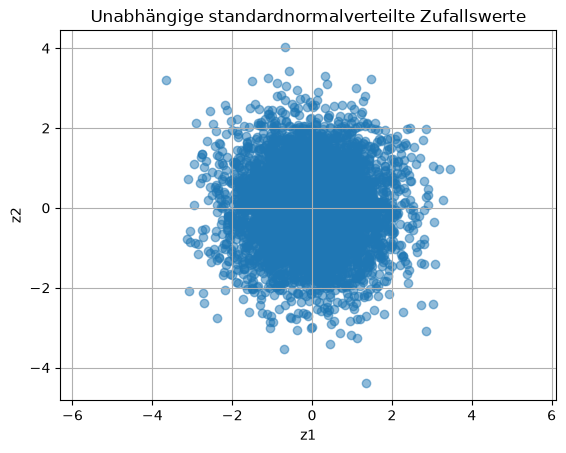

In [9]:
# Plot the independent standard normal random values
plt.scatter(z[0], z[1], alpha=0.5)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Unabhängige standardnormalverteilte Zufallswerte")
plt.axis("equal")
plt.grid(True)
plt.show()

In [20]:
# Define the parameters of the multivariate normal distribution
mean = np.array([1, 1]) # Mean of the distribution
sigma = np.array([[2, 0], [0, 0.5]]) # Covariance matrix of the distribution

## Hier kommt nun der wichtige Part

Die random generierten Werte in Z sind Gaußvertiel mit einem mean = 0 und einer Einheitskovarianzmatrix, sie streuen also unkorreliert um 0. Diese Verhalten wird nun angepasst mit Hilfe der cholesky-Transformation. Sie streuen dann um den gewünschten Mittelwert uns haben diegewünschte Varinaz

In [21]:
# Create correlated random values using the Cholesky decomposition
L = np.linalg.cholesky(sigma) # Cholesky decomposition of the covariance matrix
y  = mean[:, np.newaxis] + L @ z # Transform the standard normal data to follow the desired distribution

In [22]:
print("Simulated mean:")
print(y.mean(axis=1))

print("\nSimulated covariance:")
print(np.cov(y))

Simulated mean:
[0.97188962 0.99955968]

Simulated covariance:
[[ 1.99781848 -0.03416629]
 [-0.03416629  0.51326629]]


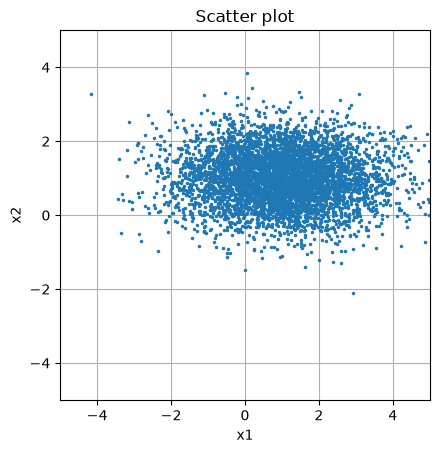

In [23]:
fig, ax = plt.subplots()

ax.plot(y[0, :], y[1, :], ".", markersize=3)
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_aspect("equal", adjustable="box")
ax.grid(True)
ax.set_title("Scatter plot")
ax.set_xlabel("x1")
ax.set_ylabel("x2")

plt.show()

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Schritt 1: System und Rauschstaerken festlegen.
# Q = Prozessrauschvarianz, R = Messrauschvarianz.
Q = 1.0
R = 1.0
A, B, C, D = 1.0, 1.0, 1.0, 0.0
max_iter = 40

# Reproduzierbare Zufallszahlen; NumPy erzeugt nicht dieselbe Folge wie Octave.
rng_kf = np.random.default_rng(10)

# Schritt 2: Anfangswerte und Speicher vorbereiten.
x_true = 0.0  # wirklicher Zustand
x_hat = 0.0   # Schaetzung des Filters
P = 0.0       # Unsicherheit der Schaetzung (Varianz)
u = 0.0       # Anfangseingang

x_true_store = np.zeros(max_iter + 1)  # x_0 bis x_40
x_hat_store = np.zeros(max_iter)       # Schaetzungen fuer 40 Messungen
P_store = np.zeros(max_iter)           # Schaetzunsicherheit nach jedem Update
x_true_store[0] = x_true